# Historical 50-world recovery studies · compact result analysis

**Archived studies, not a new PR1 pipeline run.** Original source commit `4dc69ce`; historical approved report run IDs and receipt/checksum inventory are shown below. The approvals of Teemu Säilynoja (Plannotator `pn-2a768e`) cover the *old exact report identities*, not this notebook or a new fit. These two experiments use different baseline/outcome regimes and objectives: **do not rank TV-MCMC against bounded least squares**. No inference runs when this notebook executes. All visible figures are static PNG, and all tables are saved HTML outputs.

The TV baseline was applied as a matched baseline-only intervention on the constant corpus; it was not an independent draw from the PR1 varying example. Score only the 97 original weeks 7–103, using the 10%-of-true-channel norm or 1%-of-noiseless-outcome norm (whichever greater); a computationally unresolved fit is neither a recovery pass nor a recovery failure. Components, point gates, pattern groups and descriptors are recomputed from local compressed float64 contributions, spend and recorded status/metadata.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from analysis import LABELS, load_snapshot, summarize, trajectory

root = Path.cwd()
meta, arrays = load_snapshot(root)  # validates payload hashes, historical IDs, arrays and term/ledger inventory
report = summarize(meta, arrays)
print('Validated compact snapshot:', len(report['world_rows']), 'world-method rows;', len(report['channel_rows']), 'channel rows; 97 scored weeks')


Validated compact snapshot: 100 world-method rows; 1598 channel rows; 97 scored weeks


## Historical provenance and approved narratives

Checksums below identify the *historical approved* reports and this compact copy. The old reports seal the evidence they read, but legacy source manifests contain **input hashes only**; missing original per-fit output and generator-source hashes cannot be retroactively certified. `historical-config.json` records the full original generator prior plus distinct matched-TV intervention, bounded optimizer and TV-NUTS settings. `provenance.json` contains the complete historical review/evidence/interpretation receipt hashes and every compact payload checksum. The byte-identical original interpretations are [`tv50.md`](tv50.md) and [`bounded50.md`](bounded50.md); their own headers name the older report IDs. No newly approved interpretation is claimed.

In [2]:
import json
provenance = json.loads((root / 'provenance.json').read_text())
display(pd.DataFrame([{'historical_regime': LABELS[method],
    'approved_old_run_id': record['historical_report_run_id'],
    'source_evidence_sha256': record['original_evidence_sha256'],
    'review_id': record['historical_review_id'],
    'interpretation_sha256': record['interpretation_sha256']}
    for method, record in provenance['historical_approvals'].items()]))
display(pd.DataFrame([{'compact_file': name, 'sha256': digest}
    for name, digest in provenance['compact_payload_sha256'].items()]))


,historical_regime,approved_old_run_id,source_evidence_sha256,review_id,interpretation_sha256
0,Historical TV-MCMC,f2dccfb682b95c9e8da4ffdc0d3f8c5f4134098468d54e...,9a657354105b82edebe4f2054024d6d393820f6b5af99b...,15a972d9798d4f1c7631264c77fc7fa4da317a6fb9d865...,d4e2a598f084051fbe2bd80aa102a7907aa91fb9aa8449...
1,Historical constant-baseline bounded least squ...,041a2b4bfc17d53631ad524508fe0a6243c8bdf50df47e...,ed2ed262b390c5a673b38af1c5ada010f4650f551e6209...,031ec6a9b96dfa8e7fdd2821cc25eabcef482c87a36082...,ebefc14f94406efb2c0391a0035dcbc7420aa28ec9fd6f...


,compact_file,sha256
0,historical-config.json,67eef75e4e45dcc0a27a073a580e717b53fa2d623657a7...
1,snapshot.json,c484a86a3cd4b42347f5e243f5b0be9f10a00cb5441c72...
2,snapshot.npz,b3a445e9e13e68116c2d5dd9e997ab27b56ce0ddac8fe7...
3,tv50.md,d4e2a598f084051fbe2bd80aa102a7907aa91fb9aa8449...
4,bounded50.md,ebefc14f94406efb2c0391a0035dcbc7420aa28ec9fd6f...


## World-level recovery gates (not a cross-regime comparison)

Every individual nonzero media channel must pass for `media_pass`; `joint_pass` additionally requires every nonzero control. The total-media sum and intrinsic baseline are **separate** point estimands; all four world gates use the same historic 10% / 1% L2 allowance. The 2 bounded optimizer worlds 6 and 9 are unresolved, not attribution failures. An optimization stopping rule and an MCMC diagnostics pass are computational qualifications, *not* proofs of global optimum, posterior mode coverage or individual-parameter identifiability.

,regime,worlds,valid,unresolved,unresolved_ids,media_pass,joint_pass,total_media_pass,baseline_pass
0,Historical TV-MCMC,50,50,0,[],11,9,36,36
1,Historical constant-baseline bounded least squ...,50,48,2,"[6, 9]",13,13,28,26


,regime,estimand,passes,evaluable_worlds,unresolved_worlds
0,Historical TV-MCMC,All individual media,11,50,0
1,Historical TV-MCMC,All media and controls,9,50,0
2,Historical TV-MCMC,Total-media trajectory,36,50,0
3,Historical TV-MCMC,Baseline trajectory,36,50,0
4,Historical constant-baseline bounded least squ...,All individual media,13,48,2
5,Historical constant-baseline bounded least squ...,All media and controls,13,48,2
6,Historical constant-baseline bounded least squ...,Total-media trajectory,28,48,2
7,Historical constant-baseline bounded least squ...,Baseline trajectory,26,48,2


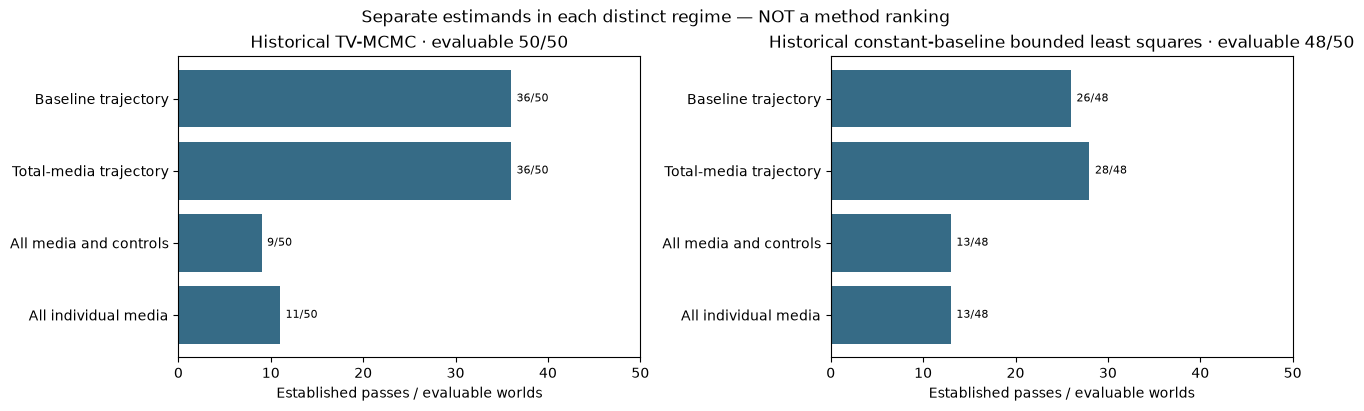

In [3]:
counts = pd.DataFrame(report['counts'])
display(counts[['regime','worlds','valid','unresolved','unresolved_ids',
                'media_pass','joint_pass','total_media_pass','baseline_pass']])
gate_names = [('media_pass','All individual media'),('joint_pass','All media and controls'),
              ('total_media_pass','Total-media trajectory'),('baseline_pass','Baseline trajectory')]
gates = pd.DataFrame([{'regime': c['regime'], 'estimand': text, 'passes': c[field],
    'evaluable_worlds': c['valid'], 'unresolved_worlds': c['unresolved']}
    for c in report['counts'] for field, text in gate_names])
display(gates)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for axis, (_, group) in zip(axes, gates.groupby('regime', sort=False)):
    axis.barh(group['estimand'], group['passes'], color='#366b86')
    axis.set_xlim(0, 50); axis.set_xlabel('Established passes / evaluable worlds')
    axis.set_title(group['regime'].iloc[0] + f" · evaluable {group['evaluable_worlds'].iloc[0]}/50")
    for index, row in enumerate(group.itertuples()):
        axis.text(row.passes + .6, index, f'{row.passes}/{row.evaluable_worlds}', va='center', fontsize=8)
fig.suptitle('Separate estimands in each distinct regime — NOT a method ranking')
display(fig); plt.close(fig)


## Channel denominators and overlapping generated patterns

Worlds with more channels contribute more pooled rows; these are not independent experiments. A structurally known-zero channel is not eligible even if it bears a pattern. Eligible nonzero channels in a computationally unresolved world are recorded separately from evaluable failures. Pattern counts belong to the **channel carrying the assigned pattern**, not to another failure in that world. Patterns overlap and their rates do not add; an assigned pattern need not dominate the realized input.

In [4]:
display(pd.DataFrame([{'regime': c['regime'], 'kind': kind,
    'nonzero_eligible': c[kind+'_eligible'], 'evaluable': c[kind+'_evaluable'],
    'failed': c[kind+'_failed'], 'unresolved': c[kind+'_unresolved'],
    'known_zero': c[kind+'_known_zero'],
    'failure_rate_on_evaluable': c[kind+'_failed']/c[kind+'_evaluable']}
    for c in report['counts'] for kind in ('media','control')]))
for regime in ('tv','bounded'):
    rows = [r for r in report['pattern_rows'] if r['regime']==regime and r['kind']=='media']
    display(Markdown('### ' + LABELS[regime] + ' · media pattern-bearing channels'))
    display(pd.DataFrame(rows)[['pattern','total','eligible','known_zero','evaluable',
        'failed','unresolved','failure_rate','small_count_warning']])


,regime,kind,nonzero_eligible,evaluable,failed,unresolved,known_zero,failure_rate_on_evaluable
0,Historical TV-MCMC,media,236,236,144,0,251,0.610169
1,Historical TV-MCMC,control,148,148,19,0,164,0.128378
2,Historical constant-baseline bounded least squ...,media,236,211,122,25,251,0.578199
3,Historical constant-baseline bounded least squ...,control,148,135,15,13,164,0.111111


### Historical TV-MCMC · media pattern-bearing channels

,pattern,total,eligible,known_zero,evaluable,failed,unresolved,failure_rate,small_count_warning
0,hf,441,214,227,214,130,0,0.607477,False
1,pulse,340,156,184,156,93,0,0.596154,False
2,onset,80,37,43,37,18,0,0.486486,False
3,offset,39,17,22,17,11,0,0.647059,False
4,flighting,93,45,48,45,14,0,0.311111,False
5,level_jump,76,34,42,34,19,0,0.558824,False
6,seasonal,137,73,64,73,42,0,0.575342,False
7,trend,146,67,79,67,38,0,0.567164,False
8,trend_up,72,35,37,35,19,0,0.542857,False
9,trend_down,74,32,42,32,19,0,0.593750,False


### Historical constant-baseline bounded least squares · media pattern-bearing channels

,pattern,total,eligible,known_zero,evaluable,failed,unresolved,failure_rate,small_count_warning
0,hf,441,214,227,193,109,21,0.564767,False
1,pulse,340,156,184,139,79,17,0.568345,False
2,onset,80,37,43,34,12,3,0.352941,False
3,offset,39,17,22,16,5,1,0.312500,False
4,flighting,93,45,48,39,16,6,0.410256,False
5,level_jump,76,34,42,28,19,6,0.678571,False
6,seasonal,137,73,64,71,32,2,0.450704,False
7,trend,146,67,79,60,32,7,0.533333,False
8,trend_up,72,35,37,32,17,3,0.531250,False
9,trend_down,74,32,42,28,15,4,0.535714,False


## TV-MCMC: computational screen and descriptive contribution variation

Only the TV regime has posterior intervals (saved **pointwise** 95% intervals, not simultaneous trajectory or held-out calibration). True generated parameter/trajectory descriptors for passing and failing nonzero media channels are observational associations, not isolated causal effects or a generator tuning rule. Group sizes in the table and scatter legend are recomputed from the compact snapshot. Noise SD is the realized scored-window observation-noise SD; observed-sales mean is the denominator for the noise-fraction quartiles. CV = temporal SD / absolute temporal mean; medians include no rounding until display.

,divergences,maxdepth_hits,max_rhat,min_bulk_ess,min_tail_ess,min_bfmi,all_pass
0,0,0,1.006906,1061.543691,1167.561448,0.623517,True


,TV media,count,saturation_mean,alpha,beta,spend_cv,contribution_cv,contribution_sd_per_noise_sd
0,Passing,92,0.417224,0.450832,2.414183,0.716084,0.340641,1.573057
1,Failing,144,0.513086,0.547068,2.628044,0.581919,0.228832,0.781619


,noise_SD / mean_observed_sales,TV_world_fraction
0,25th percentile,0.010859
1,median,0.018586
2,75th percentile,0.034791


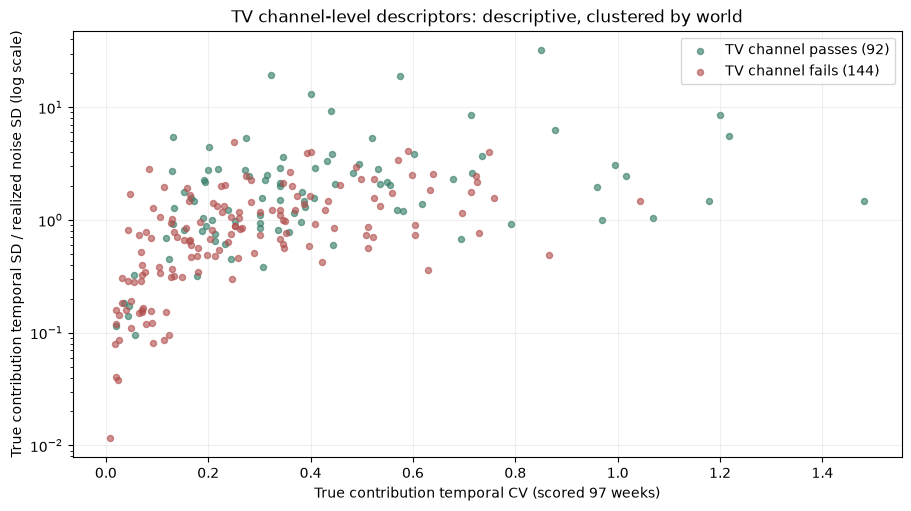

In [5]:
display(pd.DataFrame([report['tv_diagnostics']]))
display(pd.DataFrame(report['tv_descriptor_medians']))
display(pd.DataFrame([{'noise_SD / mean_observed_sales': label, 'TV_world_fraction': value}
    for label, value in zip(('25th percentile','median','75th percentile'),
                            report['tv_noise_fraction_quartiles'])]))
passed = [r for r in report['tv_descriptors'] if r['point_pass'] is True]
failed = [r for r in report['tv_descriptors'] if r['point_pass'] is False]
fig, axis = plt.subplots(figsize=(9, 5), layout='constrained')
for group, text, color in [(passed, 'TV channel passes', '#347b66'),
                           (failed, 'TV channel fails', '#b14f4d')]:
    axis.scatter([x['contribution_cv'] for x in group],
                 [x['contribution_sd_per_noise_sd'] for x in group],
                 s=19, alpha=.62, color=color, label=f'{text} ({len(group)})')
axis.set_xlabel('True contribution temporal CV (scored 97 weeks)')
axis.set_yscale('log')  # all eligible signal/noise ratios are positive; show small ones too
axis.set_ylabel('True contribution temporal SD / realized noise SD (log scale)')
axis.set_title('TV channel-level descriptors: descriptive, clustered by world')
axis.legend(); axis.grid(alpha=.2)
display(fig); plt.close(fig)


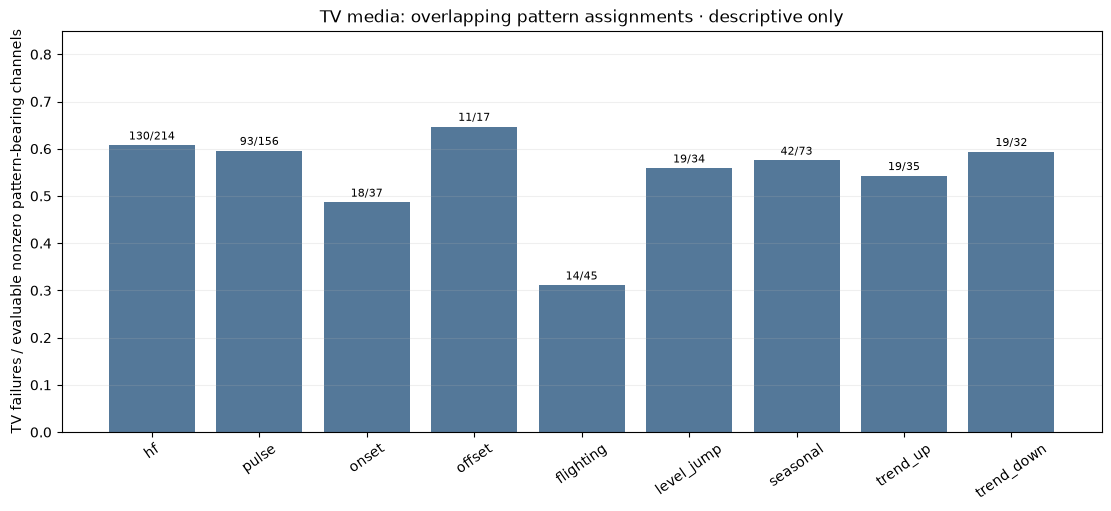

In [6]:
tv_patterns = [r for r in report['pattern_rows'] if r['regime']=='tv' and
               r['kind']=='media' and r['pattern']!='trend']  # directional trend categories instead of duplicate union
fig, axis = plt.subplots(figsize=(11, 5), layout='constrained')
axis.bar([r['pattern'] for r in tv_patterns], [r['failure_rate'] for r in tv_patterns], color='#547899')
for i, row in enumerate(tv_patterns):
    axis.text(i, row['failure_rate']+.012, f"{row['failed']}/{row['evaluable']}", ha='center', fontsize=8)
axis.set_ylim(0,.85); axis.tick_params(axis='x', labelrotation=35)
axis.set_ylabel('TV failures / evaluable nonzero pattern-bearing channels')
axis.set_title('TV media: overlapping pattern assignments · descriptive only')
axis.grid(axis='y',alpha=.2)
display(fig); plt.close(fig)


## Four **illustrative, preselected** paths · NOT representative cases

World **0**: TV channel **C2** fails its point gate; bounded channel **C3** also fails its *separately evaluated* point gate. World **12**: C6 passes its within-regime gate in each distinct baseline/outcome study. These channel IDs were chosen explicitly to show a valid failed and valid passing channel **within** each regime; they are not a matched algorithm comparison, typical-world estimate or automatic cherry-picked headline statistic. The plotted raw input is shared between regimes; the TV plot's shading is pointwise posterior intervals only. Figures display raw spend and the true/fitted baseline so differing baselines are not hidden.

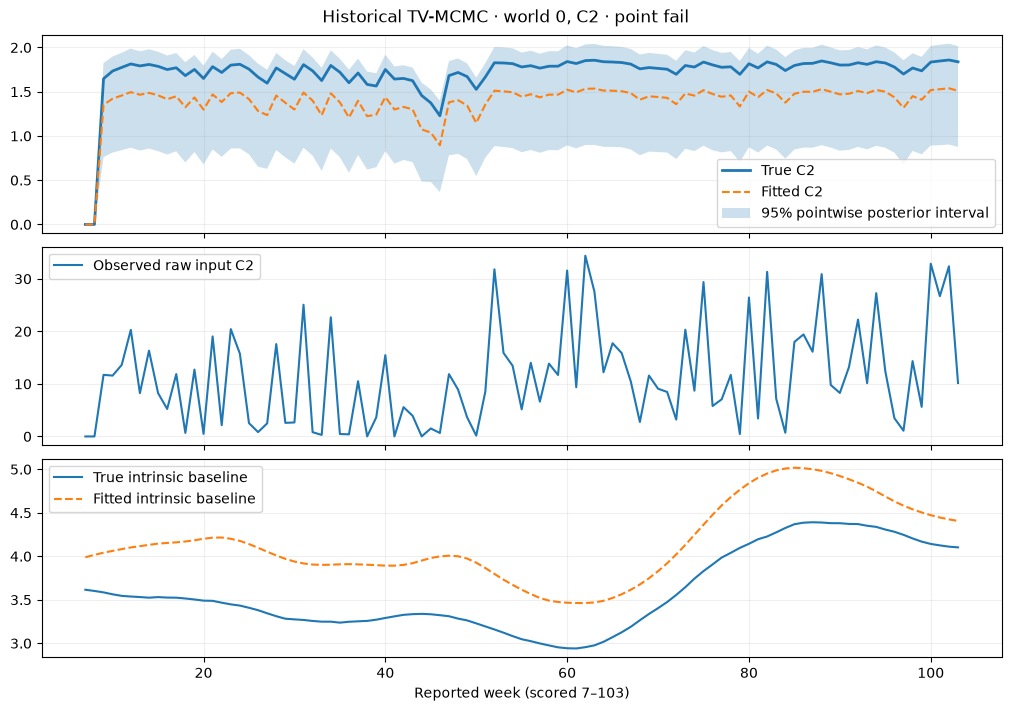

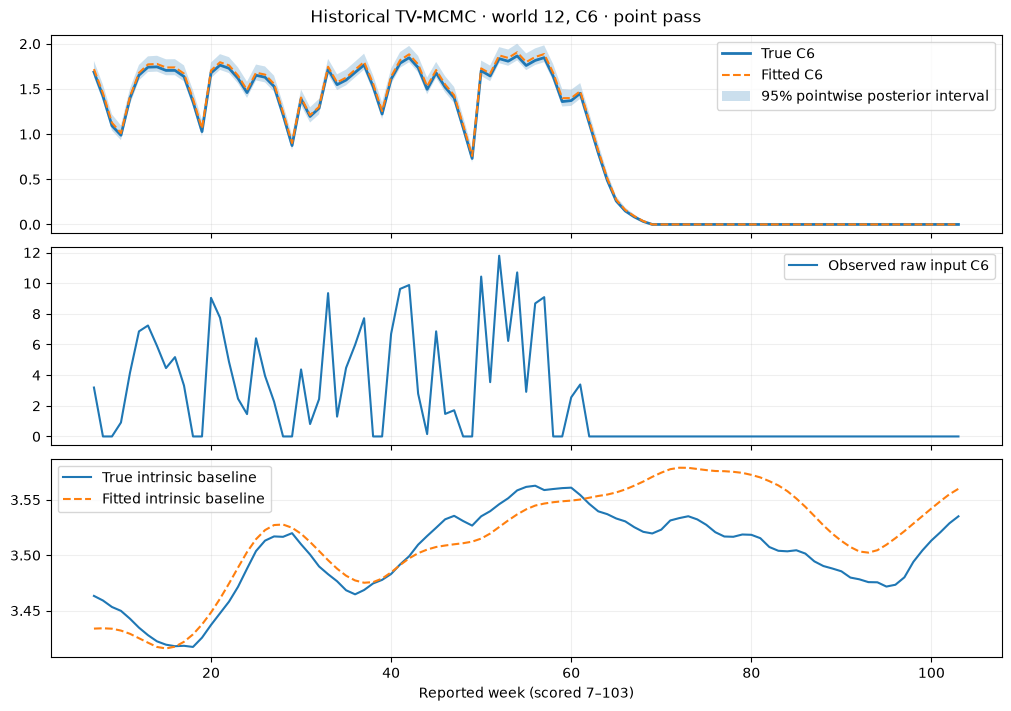

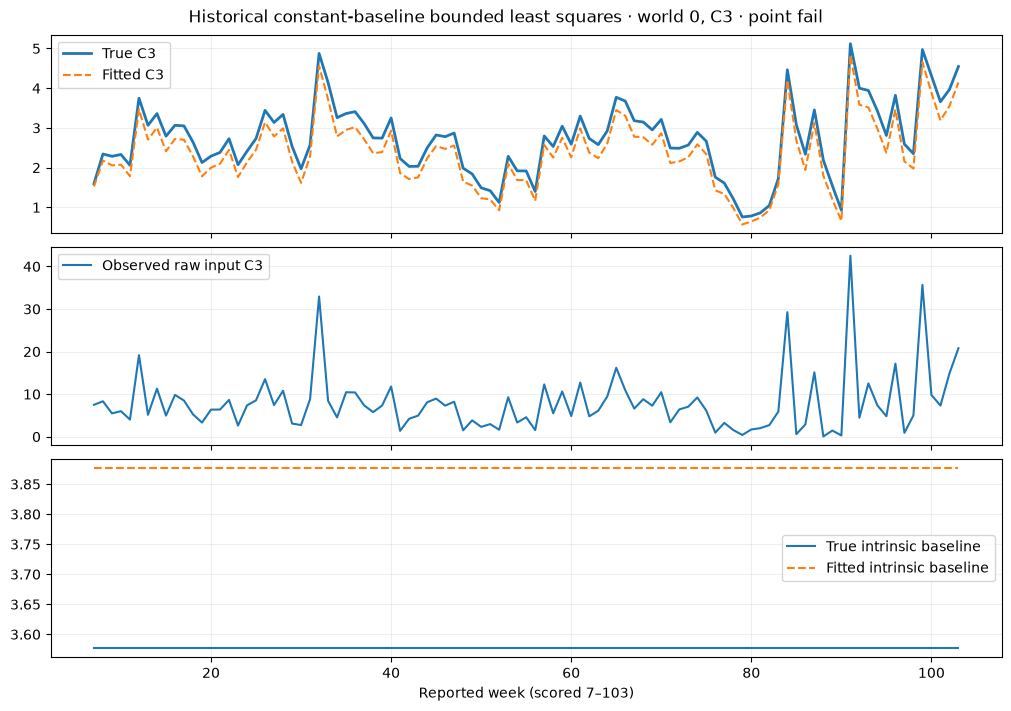

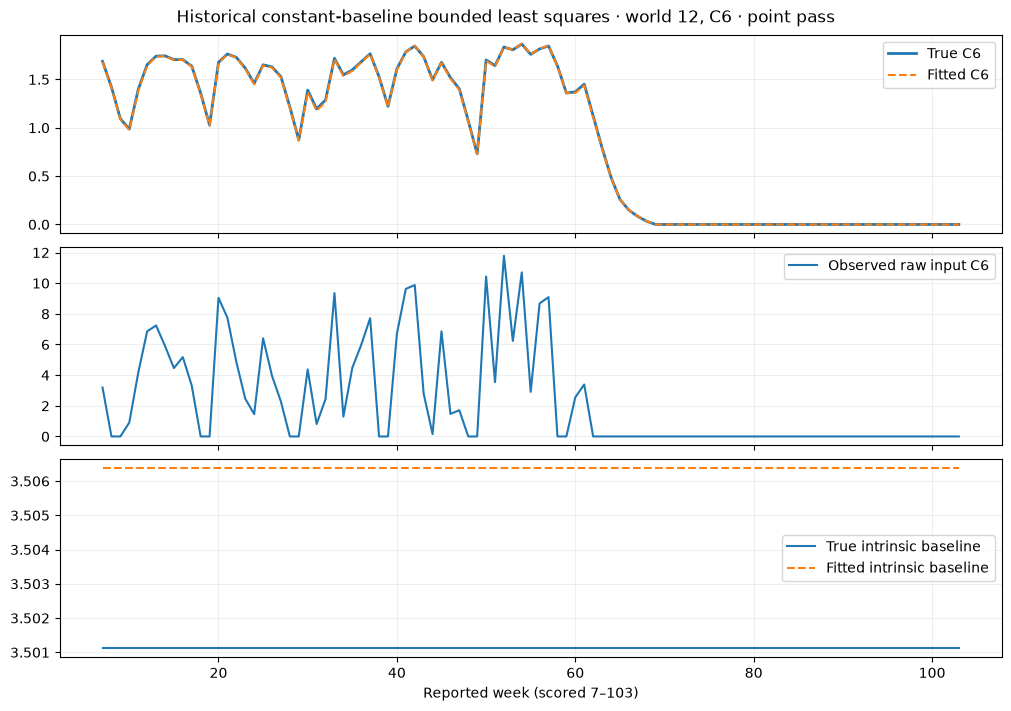

In [7]:
for regime, world, channel, expected in [('tv',0,'C2',False),('tv',12,'C6',True),
                                          ('bounded',0,'C3',False),('bounded',12,'C6',True)]:
    rec = next(r for r in report['channel_rows'] if r['regime']==regime and
               r['world_id']==world and r['channel']==channel)
    assert rec['point_pass'] is expected
    path = trajectory(meta, arrays, regime, world)
    i = path['terms'].index(channel)
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout='constrained')
    x = path['weeks']
    axes[0].plot(x,path['truth'][:,i],label='True '+channel,linewidth=2)
    axes[0].plot(x,path['fitted'][:,i],linestyle='--',label='Fitted '+channel)
    if path['lower95'] is not None:
        axes[0].fill_between(x,path['lower95'][:,i],path['upper95'][:,i],
                             alpha=.23,label='95% pointwise posterior interval')
    axes[1].plot(x,path['raw_spend'][:,int(channel[1:])-1],label='Observed raw input '+channel)
    axes[2].plot(x,path['truth'][:,0],label='True intrinsic baseline')
    axes[2].plot(x,path['fitted'][:,0],linestyle='--',label='Fitted intrinsic baseline')
    for axis in axes:
        axis.grid(alpha=.2); axis.legend(loc='best')
    axes[2].set_xlabel('Reported week (scored 7–103)')
    fig.suptitle(LABELS[regime] + f' · world {world}, {channel} · point '+('pass' if expected else 'fail'))
    display(fig); plt.close(fig)


## Scientific limits and original interpretations

See the **byte-identical historically approved** [`TV narrative`](tv50.md) and [`bounded narrative`](bounded50.md) for detailed interpretation and original exact report identities. This export is a retrospective compact numerical snapshot and reproducible analysis/presentation, **not historical model/sampler regeneration or a newly approved report**. It cannot retroactively certify original source/output bytes, posterior calibration, held-out or intervention performance, real-spend realism, structural non-identifiability or an algorithm ranking. The current PR1 pipeline generates *new* supported configurations and does **not** exactly replay the historical paired-TV intervention, bounded optimizer seed-per-world rule or original TV reconstruction RNG; PR1's short smoke fits are engineering checks, not data points here.